## Experience 2 : segmentation
Comparaison de trois methodes pour segmenter la zone tumorale (masque binaire tumeur / fond) : **U-Net** (encodeur ResNet34 pre-entraine), **FCN** (meme encodeur, decodeur de type FCN-8s) et un **seuillage d'Otsu** de reference.

**Ce notebook est autonome** (constantes definies dans la premiere cellule). Dependances : `%pip install torch torchvision pillow matplotlib`.

**Materiel.** Execution sur **CPU par defaut** (`DEVICE_PREFERENCE = "cpu"`) : le noyau plantait sur MPS (Mac) dans l'experience de classification. Pour utiliser le GPU, mettre `"auto"` ou `"mps"` dans la premiere cellule.

**Execution.** Executer les cellules dans l'ordre : chaque entrainement a sa cellule, les resultats utilisent la **meilleure epoque** (Dice de validation), et la derniere cellule enregistre les figures dans `outputs/segmentation/evaluation/figures/` (courbes d'entrainement, comparaison valid / test, repartition du Dice par image, predictions sur des images de test).

In [1]:
# EXPERIENCE 2 : SEGMENTATION - CONFIGURATION
# Comparaison : U-Net (encodeur ResNet34 pre-entraine) vs FCN (meme encodeur) vs seuillage d'Otsu.
# Dependances : %pip install torch torchvision pillow matplotlib
# Les polygones YOLO des tumeurs sont transformes en masques binaires (tumeur / fond).

import os

# Doit etre defini AVANT l'import de torch : repli sur le CPU pour les operateurs absents de MPS.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import copy
import csv
import gc
import random
from pathlib import Path

import torch
import torch.nn.functional as functional
from PIL import Image, ImageDraw
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models

# Constantes (auparavant definies dans un autre notebook : celui-ci est autonome).
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SEGMENTATION_SIZE = 256
BATCH_SIZE_SEG = 8
EPOCHS_SEGMENTATION = 15
LEARNING_RATE = 1e-4
SEED = 42
PRETRAINED = True  # False = encodeurs aleatoires (utile hors ligne, sans telechargement des poids)

# "cpu" par defaut (le noyau plantait sur MPS dans l'experience de classification).
# Passer a "auto", "mps" ou "cuda" pour utiliser l'accelerateur.
DEVICE_PREFERENCE = "cpu"

DATASET_ROOT = Path("small_dataset")
segmentation_train_dir = Path("outputs/segmentation/train")
segmentation_eval_dir = Path("outputs/segmentation/evaluation")
segmentation_train_dir.mkdir(parents=True, exist_ok=True)
segmentation_eval_dir.mkdir(parents=True, exist_ok=True)

# Normalisation ImageNet (creee une seule fois).
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)


def select_device(preference):
    if preference == "cuda" and torch.cuda.is_available():
        return torch.device("cuda")
    if preference == "mps" and torch.backends.mps.is_available():
        return torch.device("mps")
    if preference == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")
        if torch.backends.mps.is_available():
            return torch.device("mps")
    return torch.device("cpu")


def free_device_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    if torch.backends.mps.is_available():
        torch.mps.empty_cache()


set_seed(SEED)
DEVICE = select_device(DEVICE_PREFERENCE)
print(f"PyTorch {torch.__version__} | materiel : {DEVICE} | batch={BATCH_SIZE_SEG} | graine={SEED}")

PyTorch 2.2.2 | materiel : cpu | batch=8 | graine=42


In [2]:
# DONNEES : image + masque binaire (union des polygones) + version en niveaux de gris (pour Otsu).
def pil_to_float_tensor(image):
    """Image PIL ("RGB" ou "L") -> tenseur float dans [0, 1], sans passer par NumPy."""
    width, height = image.size
    data = torch.frombuffer(bytearray(image.tobytes()), dtype=torch.uint8)
    if image.mode == "RGB":
        return data.view(height, width, 3).permute(2, 0, 1).float() / 255.0
    return data.view(height, width).float() / 255.0


class TumorSegmentationDataset(Dataset):
    """Charge l'image, son masque binaire et son intensite en niveaux de gris."""

    def __init__(self, split):
        self.images_dir = DATASET_ROOT / split / "images"
        self.labels_dir = DATASET_ROOT / split / "labels"
        self.image_paths = [
            image_path
            for image_path in sorted(self.images_dir.iterdir())
            if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ]
        print(f"{split}: {len(self.image_paths)} images")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        label_path = self.labels_dir / f"{image_path.stem}.txt"
        with Image.open(image_path) as source:  # fermer le fichier apres lecture
            image = source.convert("RGB")
        width, height = image.size

        # Construire un seul masque d'union, puisque l'experience porte sur la zone tumorale.
        mask_image = Image.new("L", (width, height), 0)
        draw = ImageDraw.Draw(mask_image)
        if label_path.is_file():
            for line in label_path.read_text(encoding="utf-8").splitlines():
                fields = line.split()
                if len(fields) < 7:
                    continue
                try:
                    coordinates = [float(value) for value in fields[1:]]
                except ValueError:
                    continue
                if len(coordinates) % 2:
                    continue
                points = [
                    (
                        min(max(value_x, 0.0), 1.0) * (width - 1),
                        min(max(value_y, 0.0), 1.0) * (height - 1),
                    )
                    for value_x, value_y in zip(coordinates[::2], coordinates[1::2])
                ]
                if len(points) >= 3:
                    draw.polygon(points, fill=255)

        # Redimensionner l'image et le masque avec l'interpolation adaptee a chacun.
        image = image.resize((SEGMENTATION_SIZE, SEGMENTATION_SIZE), Image.Resampling.BILINEAR)
        gray_tensor = pil_to_float_tensor(image.convert("L"))
        mask_image = mask_image.resize((SEGMENTATION_SIZE, SEGMENTATION_SIZE), Image.Resampling.NEAREST)
        mask_tensor = pil_to_float_tensor(mask_image).unsqueeze(0)  # 0.0 ou 1.0
        image_tensor = (pil_to_float_tensor(image) - IMAGENET_MEAN) / IMAGENET_STD
        return image_tensor, mask_tensor, gray_tensor


# Chargeurs sur les memes images et masques pour tous les modeles.
segmentation_datasets = {split: TumorSegmentationDataset(split) for split in ("train", "valid", "test")}
if any(len(dataset) == 0 for dataset in segmentation_datasets.values()):
    raise ValueError("Au moins un split ne contient aucune image.")
segmentation_loaders = {
    split: DataLoader(
        dataset,
        batch_size=BATCH_SIZE_SEG,
        shuffle=(split == "train"),
        num_workers=0,
        generator=torch.Generator().manual_seed(SEED) if split == "train" else None,
    )
    for split, dataset in segmentation_datasets.items()
}

train: 300 images
valid: 150 images
test: 150 images


In [3]:
# MODELES : U-Net et FCN partagent le meme encodeur ResNet34, seul le decodeur change.
def load_resnet34_encoder():
    try:
        return models.resnet34(weights=models.ResNet34_Weights.DEFAULT if PRETRAINED else None)
    except Exception as error:  # telechargement impossible (hors ligne, proxy...)
        raise RuntimeError(
            "Impossible de charger les poids ImageNet de ResNet34. Verifier la connexion ou "
            "mettre PRETRAINED = False (la comparaison perd alors son sens)."
        ) from error


# Bloc de decoder U-Net : remonter en resolution et fusionner le skip connection.
class DecoderBlock(nn.Module):
    def __init__(self, input_channels, skip_channels, output_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(input_channels + skip_channels, output_channels, 3, padding=1),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(output_channels, output_channels, 3, padding=1),
            nn.BatchNorm2d(output_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, features, skip):
        features = functional.interpolate(features, size=skip.shape[-2:], mode="bilinear", align_corners=False)
        return self.layers(torch.cat([features, skip], dim=1))


class ResNet34UNet(nn.Module):
    """U-Net dont l'encodeur ResNet34 est initialise avec des poids ImageNet."""

    def __init__(self):
        super().__init__()
        encoder = load_resnet34_encoder()
        self.conv1, self.bn1, self.relu, self.maxpool = encoder.conv1, encoder.bn1, encoder.relu, encoder.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4
        self.decode4 = DecoderBlock(512, 256, 256)
        self.decode3 = DecoderBlock(256, 128, 128)
        self.decode2 = DecoderBlock(128, 64, 64)
        self.decode1 = DecoderBlock(64, 64, 64)
        # CORRECTION : decode0 n'etait jamais appele (la tete 32 canaux recevait 64 canaux : plantage).
        # Dernier niveau a pleine resolution, avec l'image d'entree (3 canaux) comme skip connection.
        self.decode0 = DecoderBlock(64, 3, 32)
        self.mask_head = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, images):
        stem = self.relu(self.bn1(self.conv1(images)))          # H/2, 64 canaux
        feature1 = self.layer1(self.maxpool(stem))              # H/4, 64
        feature2 = self.layer2(feature1)                        # H/8, 128
        feature3 = self.layer3(feature2)                        # H/16, 256
        feature4 = self.layer4(feature3)                        # H/32, 512
        decoded = self.decode4(feature4, feature3)
        decoded = self.decode3(decoded, feature2)
        decoded = self.decode2(decoded, feature1)
        decoded = self.decode1(decoded, stem)
        decoded = self.decode0(decoded, images)
        return self.mask_head(decoded)


class ResNet34FCN(nn.Module):
    """FCN style FCN-8s : scores 1x1 des niveaux 1/32, 1/16 et 1/8, sommes puis sur-echantillonnes.

    Meme encodeur ResNet34 pre-entraine que le U-Net : la comparaison porte sur le decodeur.
    """

    def __init__(self):
        super().__init__()
        encoder = load_resnet34_encoder()
        self.conv1, self.bn1, self.relu, self.maxpool = encoder.conv1, encoder.bn1, encoder.relu, encoder.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = encoder.layer1, encoder.layer2, encoder.layer3, encoder.layer4
        self.score4 = nn.Conv2d(512, 1, kernel_size=1)
        self.score3 = nn.Conv2d(256, 1, kernel_size=1)
        self.score2 = nn.Conv2d(128, 1, kernel_size=1)

    def forward(self, images):
        size = images.shape[-2:]
        stem = self.relu(self.bn1(self.conv1(images)))
        feature1 = self.layer1(self.maxpool(stem))
        feature2 = self.layer2(feature1)
        feature3 = self.layer3(feature2)
        feature4 = self.layer4(feature3)
        score = self.score4(feature4)
        score = functional.interpolate(score, size=feature3.shape[-2:], mode="bilinear", align_corners=False)
        score = score + self.score3(feature3)
        score = functional.interpolate(score, size=feature2.shape[-2:], mode="bilinear", align_corners=False)
        score = score + self.score2(feature2)
        return functional.interpolate(score, size=size, mode="bilinear", align_corners=False)


# Perte combinee : BCE pour les pixels et Dice pour le recouvrement global.
def segmentation_loss(logits, targets):
    bce = nn.functional.binary_cross_entropy_with_logits(logits, targets)
    probabilities = torch.sigmoid(logits)
    intersection = (probabilities * targets).sum(dim=(1, 2, 3))
    denominator = probabilities.sum(dim=(1, 2, 3)) + targets.sum(dim=(1, 2, 3))
    dice_loss = 1 - ((2 * intersection + 1) / (denominator + 1)).mean()
    return bce + dice_loss


def dice_iou_per_image(predictions, targets):
    """Dice et IoU de chaque image (masques binaires deja seuilles) : deux tenseurs de taille B."""
    predictions = predictions.bool()
    targets = targets.bool()
    intersection = (predictions & targets).sum(dim=(1, 2, 3)).float()
    union = (predictions | targets).sum(dim=(1, 2, 3)).float()
    predicted_area = predictions.sum(dim=(1, 2, 3)).float()
    target_area = targets.sum(dim=(1, 2, 3)).float()
    dice = (2 * intersection + 1e-6) / (predicted_area + target_area + 1e-6)
    iou = (intersection + 1e-6) / (union + 1e-6)
    return dice, iou


# Seuil d'Otsu calcule avec torch (sans NumPy) : renvoie le niveau de gris (0-255) de coupure.
def otsu_level(gray_image):
    levels = (gray_image * 255).round().long().flatten()  # arrondi : (x * 255) tronque faussait l'histogramme
    histogram = torch.bincount(levels, minlength=256).double()
    probabilities = histogram / histogram.sum()
    cumulative_probability = probabilities.cumsum(0)
    cumulative_mean = (probabilities * torch.arange(256, dtype=torch.double)).cumsum(0)
    between_class_variance = (
        (cumulative_mean[-1] * cumulative_probability - cumulative_mean) ** 2
        / (cumulative_probability * (1 - cumulative_probability) + 1e-12)
    )
    return int(between_class_variance.argmax())


def otsu_mask(gray_image):
    """Pixels strictement plus clairs que le seuil (classe 'clair' d'Otsu), comparaison sur entiers."""
    return (gray_image * 255).round().long() > otsu_level(gray_image)


# Predicteurs : (images normalisees, niveaux de gris) -> masques booleens (B, 1, H, W) sur CPU.
def model_predictor(model):
    @torch.no_grad()
    def predict(images, gray_images):
        model.eval()
        return (torch.sigmoid(model(images.to(DEVICE))) >= 0.5).cpu()

    return predict


def otsu_predictor(images, gray_images):
    return torch.stack([otsu_mask(gray) for gray in gray_images]).unsqueeze(1)


def collect_scores(predictor, split):
    """Dice et IoU de chaque image du split, dans l'ordre du jeu de donnees (test non melange)."""
    dice_values, iou_values = [], []
    for images, masks, gray_images in segmentation_loaders[split]:
        dice, iou = dice_iou_per_image(predictor(images, gray_images), masks >= 0.5)
        dice_values += dice.tolist()
        iou_values += iou.tolist()
    return dice_values, iou_values


def mean_scores(predictor, split):
    """Dice et IoU moyens par image (et non par lot : le dernier lot est plus petit)."""
    dice_values, iou_values = collect_scores(predictor, split)
    return sum(dice_values) / len(dice_values), sum(iou_values) / len(iou_values)


def write_history_csv(history, path):
    with Path(path).open("w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)


# Meme boucle, meme nombre d'epoques et meme taux d'apprentissage pour comparer U-Net et FCN.
def train_segmentation(model, model_name, slug):
    set_seed(SEED)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    history = []
    best_valid_dice = -1.0
    best_state = None
    best_epoch = 0

    for epoch in range(EPOCHS_SEGMENTATION):
        model.train()
        total_loss = 0.0
        for images, masks, _ in segmentation_loaders["train"]:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            optimizer.zero_grad()
            loss = segmentation_loss(model(images), masks)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        train_loss = total_loss / len(segmentation_loaders["train"])
        valid_dice, valid_iou = mean_scores(model_predictor(model), "valid")
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "valid_dice": valid_dice, "valid_iou": valid_iou})
        print(
            f"{model_name} | epoque {epoch + 1}/{EPOCHS_SEGMENTATION} | perte train {train_loss:.4f} | "
            f"Dice valid {valid_dice:.4f} | IoU valid {valid_iou:.4f}"
        )

        # Meilleure epoque selon le Dice de validation (copie sur CPU).
        if valid_dice > best_valid_dice:
            best_valid_dice, best_epoch = valid_dice, epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(
                {"epoch": best_epoch, "model_state_dict": best_state, "image_size": SEGMENTATION_SIZE},
                segmentation_train_dir / f"{slug}_best.pth",
            )
        # Dernier etat pour reprendre apres un arret du noyau.
        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                "optimizer_state_dict": optimizer.state_dict(),
                "history": history,
                "image_size": SEGMENTATION_SIZE,
            },
            segmentation_train_dir / f"{slug}_latest.pth",
        )
        write_history_csv(history, segmentation_train_dir / f"{slug}_history.csv")

    # Le modele conserve est celui de la meilleure epoque (choisie sur valid, jamais sur test).
    model.load_state_dict(best_state)
    print(f"{model_name} | meilleure epoque : {best_epoch} (Dice valid {best_valid_dice:.4f})")
    model = model.cpu()
    del optimizer
    free_device_memory()
    return model, history, best_epoch

In [4]:
# ENTRAINEMENT 1/2 : U-Net (encodeur ResNet34)
unet_model, unet_history, unet_best_epoch = train_segmentation(ResNet34UNet(), "U-Net ResNet8", "unet_resnet8")

U-Net ResNet8 | epoque 1/15 | perte train 1.5268 | Dice valid 0.2914 | IoU valid 0.1841
U-Net ResNet8 | epoque 2/15 | perte train 1.3433 | Dice valid 0.6094 | IoU valid 0.4973
U-Net ResNet8 | epoque 3/15 | perte train 1.2911 | Dice valid 0.6621 | IoU valid 0.5462
U-Net ResNet8 | epoque 4/15 | perte train 1.2585 | Dice valid 0.6608 | IoU valid 0.5318
U-Net ResNet8 | epoque 5/15 | perte train 1.2354 | Dice valid 0.7124 | IoU valid 0.6040
U-Net ResNet8 | epoque 6/15 | perte train 1.2084 | Dice valid 0.7225 | IoU valid 0.6137
U-Net ResNet8 | epoque 7/15 | perte train 1.1875 | Dice valid 0.7506 | IoU valid 0.6362
U-Net ResNet8 | epoque 8/15 | perte train 1.1711 | Dice valid 0.7603 | IoU valid 0.6525
U-Net ResNet8 | epoque 9/15 | perte train 1.1511 | Dice valid 0.7695 | IoU valid 0.6657
U-Net ResNet8 | epoque 10/15 | perte train 1.1297 | Dice valid 0.7725 | IoU valid 0.6771
U-Net ResNet8 | epoque 11/15 | perte train 1.1102 | Dice valid 0.7751 | IoU valid 0.6790
U-Net ResNet8 | epoque 12/15 |

In [5]:
# ENTRAINEMENT 2/2 : FCN (meme encodeur ResNet34) - cellule separee : un plantage ne perd pas le U-Net.
fcn_model, fcn_history, fcn_best_epoch = train_segmentation(ResNet34FCN(), "FCN ResNet8", "fcn_resnet8")

FCN ResNet8 | epoque 1/15 | perte train 1.2869 | Dice valid 0.3711 | IoU valid 0.2523
FCN ResNet8 | epoque 2/15 | perte train 0.7067 | Dice valid 0.5837 | IoU valid 0.4616
FCN ResNet8 | epoque 3/15 | perte train 0.5030 | Dice valid 0.6275 | IoU valid 0.5099
FCN ResNet8 | epoque 4/15 | perte train 0.3986 | Dice valid 0.6861 | IoU valid 0.5669
FCN ResNet8 | epoque 5/15 | perte train 0.3333 | Dice valid 0.6978 | IoU valid 0.5857
FCN ResNet8 | epoque 6/15 | perte train 0.2771 | Dice valid 0.7419 | IoU valid 0.6337
FCN ResNet8 | epoque 7/15 | perte train 0.2406 | Dice valid 0.7369 | IoU valid 0.6320
FCN ResNet8 | epoque 8/15 | perte train 0.2160 | Dice valid 0.7440 | IoU valid 0.6375
FCN ResNet8 | epoque 9/15 | perte train 0.2012 | Dice valid 0.7511 | IoU valid 0.6487
FCN ResNet8 | epoque 10/15 | perte train 0.1825 | Dice valid 0.7502 | IoU valid 0.6481
FCN ResNet8 | epoque 11/15 | perte train 0.1696 | Dice valid 0.7700 | IoU valid 0.6674
FCN ResNet8 | epoque 12/15 | perte train 0.1608 | Di

In [6]:
# EVALUATION (valid et test) du U-Net, du FCN et du seuillage d'Otsu, puis SAUVEGARDE.
segmentation_models = {"unet_resnet34": unet_model, "fcn_resnet34": fcn_model}
segmentation_best_epochs = {"unet_resnet34": unet_best_epoch, "fcn_resnet34": fcn_best_epoch}

segmentation_results = []
for split in ("valid", "test"):
    for method, model in segmentation_models.items():
        model.to(DEVICE)
        dice, iou = mean_scores(model_predictor(model), split)
        model.cpu()
        segmentation_results.append({"method": method, "split": split, "dice": dice, "iou": iou})
    dice, iou = mean_scores(otsu_predictor, split)
    segmentation_results.append({"method": "otsu", "split": split, "dice": dice, "iou": iou})
free_device_memory()

for row in segmentation_results:
    print(f"{row['split']:5s} | {row['method']:14s} | Dice={row['dice']:.4f} | IoU={row['iou']:.4f}")

# Poids finaux (meilleure epoque) et tableau des metriques.
for method, model in segmentation_models.items():
    torch.save(
        {"model_state_dict": model.state_dict(), "image_size": SEGMENTATION_SIZE,
         "best_epoch": segmentation_best_epochs[method]},
        segmentation_train_dir / f"{method}.pth",
    )
with (segmentation_eval_dir / "metrics.csv").open("w", newline="", encoding="utf-8") as csv_file:
    writer = csv.DictWriter(csv_file, fieldnames=segmentation_results[0].keys())
    writer.writeheader()
    writer.writerows(segmentation_results)

print(f"Checkpoints segmentation : {segmentation_train_dir}")
print(f"Metriques segmentation : {segmentation_eval_dir / 'metrics.csv'}")

valid | unet_resnet34  | Dice=0.7892 | IoU=0.6981
valid | fcn_resnet34   | Dice=0.7768 | IoU=0.6819
valid | otsu           | Dice=0.1039 | IoU=0.0572
test  | unet_resnet34  | Dice=0.7732 | IoU=0.6792
test  | fcn_resnet34   | Dice=0.7726 | IoU=0.6773
test  | otsu           | Dice=0.0983 | IoU=0.0542
Checkpoints segmentation : outputs/segmentation/train
Metriques segmentation : outputs/segmentation/evaluation/metrics.csv


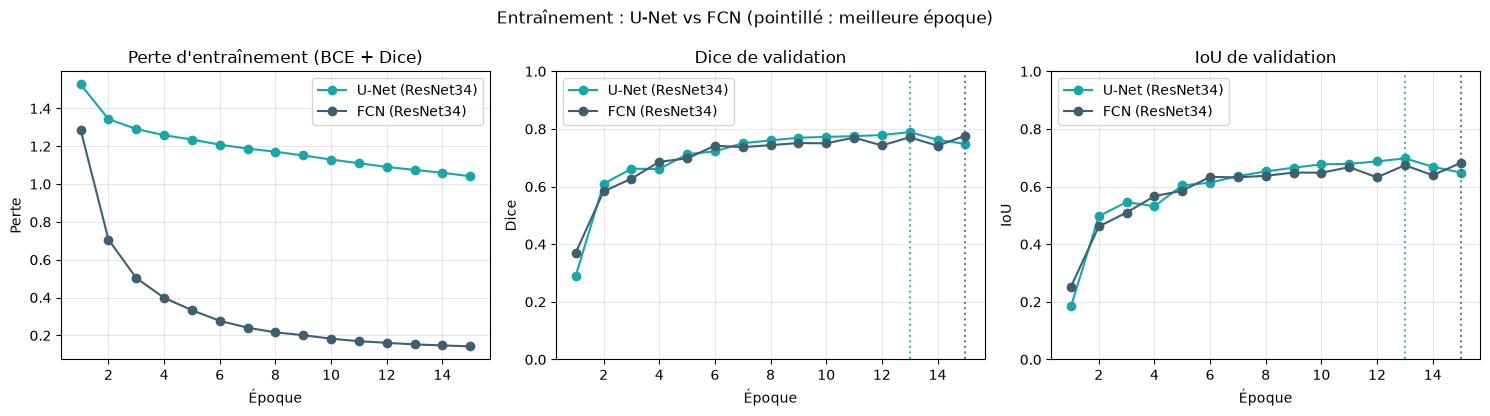

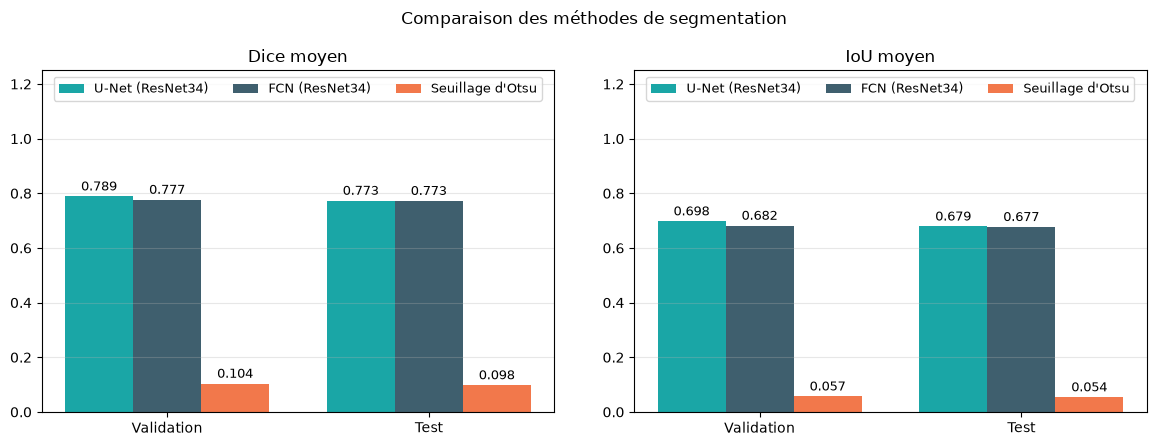

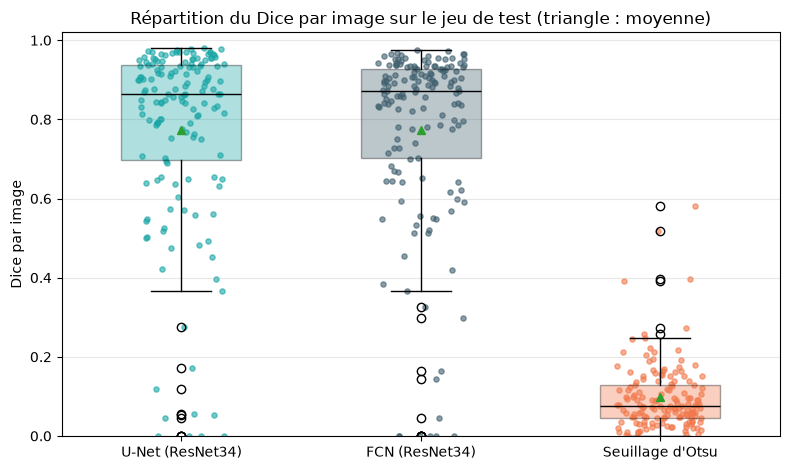

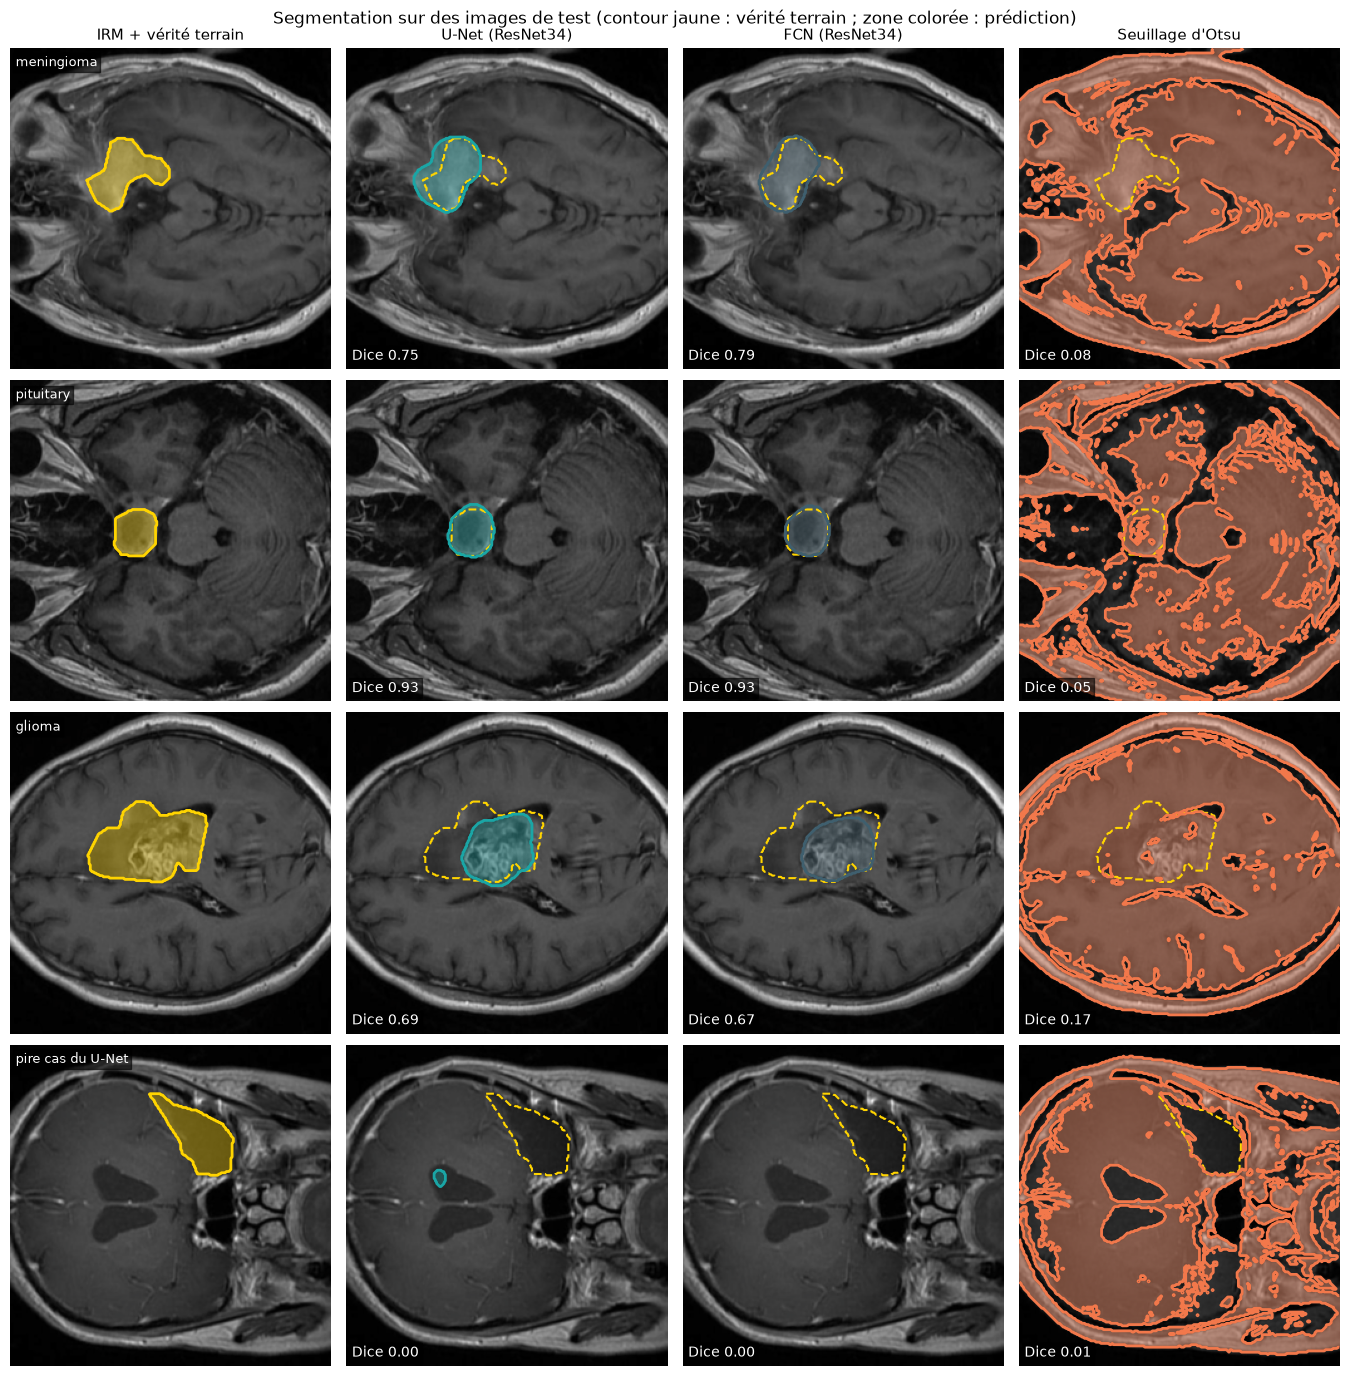

Figures de segmentation (4) dans : outputs/segmentation/evaluation/figures
  - training_curves.png
  - comparison_metrics.png
  - dice_distribution_test.png
  - test_predictions.png


In [7]:
# FIGURES : les resultats de segmentation sous forme d'images PNG.
# A executer apres la cellule d'evaluation. Dependance : %pip install matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator

SEG_FIGURES_DIR = segmentation_eval_dir / "figures"
SEG_FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEG_CLASS_NAMES = ["glioma", "meningioma", "pituitary"]
METHOD_LABELS = {"unet_resnet34": "U-Net (ResNet34)", "fcn_resnet34": "FCN (ResNet34)", "otsu": "Seuillage d'Otsu"}
METHOD_COLORS = {"unet_resnet34": "#1AA6A6", "fcn_resnet34": "#3F5F6E", "otsu": "#F2784B"}
TRUTH_COLOR = "#FFD400"
saved_segmentation_figures = []


def save_segmentation_figure(fig, file_name):
    """Enregistrer la figure en PNG (150 dpi), l'afficher dans le notebook, puis la fermer."""
    path = SEG_FIGURES_DIR / file_name
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)
    saved_segmentation_figures.append(path)


# ---------------------------------------------------------------- 1. Courbes d'entrainement
histories = {"unet_resnet34": unet_history, "fcn_resnet34": fcn_history}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for method, history in histories.items():
    epochs = [h["epoch"] for h in history]
    color = METHOD_COLORS[method]
    for ax, key in zip(axes, ("train_loss", "valid_dice", "valid_iou")):
        ax.plot(epochs, [h[key] for h in history], marker="o", color=color, label=METHOD_LABELS[method])
        if key != "train_loss":
            ax.axvline(segmentation_best_epochs[method], color=color, linestyle=":", alpha=0.8)
axes[0].set(title="Perte d'entraînement (BCE + Dice)", xlabel="Époque", ylabel="Perte")
axes[1].set(title="Dice de validation", xlabel="Époque", ylabel="Dice", ylim=(0, 1))
axes[2].set(title="IoU de validation", xlabel="Époque", ylabel="IoU", ylim=(0, 1))
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Entraînement : U-Net vs FCN (pointillé : meilleure époque)")
save_segmentation_figure(fig, "training_curves.png")


# ---------------------------------------------------------------- 2. Comparaison valid / test
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
width = 0.26
for ax, metric, title in zip(axes, ("dice", "iou"), ("Dice moyen", "IoU moyen")):
    for offset, method in zip((-width, 0, width), METHOD_LABELS):
        values = [next(r[metric] for r in segmentation_results if r["method"] == method and r["split"] == split)
                  for split in ("valid", "test")]
        bars = ax.bar([i + offset for i in range(2)], values, width, label=METHOD_LABELS[method],
                      color=METHOD_COLORS[method])
        ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=2, fontsize=9)
    ax.set_xticks(range(2), ["Validation", "Test"])
    ax.set(title=title, ylim=(0, 1.25))
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper center", ncol=3, fontsize=9)
fig.suptitle("Comparaison des méthodes de segmentation")
save_segmentation_figure(fig, "comparison_metrics.png")


# ---------------------------------------------------------------- 3. Dice image par image (test)
per_image = {}
for method, model in segmentation_models.items():
    model.to(DEVICE)
    per_image[method] = collect_scores(model_predictor(model), "test")
    model.cpu()
per_image["otsu"] = collect_scores(otsu_predictor, "test")
free_device_memory()

fig, ax = plt.subplots(figsize=(8, 4.8))
methods = list(METHOD_LABELS)
box = ax.boxplot([per_image[m][0] for m in methods], patch_artist=True, showmeans=True, widths=0.5,
                 medianprops={"color": "black"})
jitter = random.Random(SEED)
for position, method in enumerate(methods, start=1):
    box["boxes"][position - 1].set(facecolor=METHOD_COLORS[method], alpha=0.35)
    values = per_image[method][0]
    ax.scatter([position + jitter.uniform(-0.18, 0.18) for _ in values], values, s=14, alpha=0.6,
               color=METHOD_COLORS[method])
ax.set_xticks(range(1, len(methods) + 1), [METHOD_LABELS[m] for m in methods])
lowest = min(min(per_image[m][0]) for m in methods)
ax.set(ylabel="Dice par image", ylim=(max(0.0, lowest - 0.05), 1.02),
       title="Répartition du Dice par image sur le jeu de test (triangle : moyenne)")
ax.grid(axis="y", alpha=0.3)
save_segmentation_figure(fig, "dice_distribution_test.png")


# ---------------------------------------------------------------- 4. Predictions sur des images de test
test_dataset = segmentation_datasets["test"]


def image_class_name(index):
    label_path = test_dataset.labels_dir / f"{test_dataset.image_paths[index].stem}.txt"
    if label_path.is_file():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            fields = line.split()
            if fields and fields[0].isdigit() and int(fields[0]) < len(SEG_CLASS_NAMES):
                return SEG_CLASS_NAMES[int(fields[0])]
    return "sans tumeur"


# Une image par classe (la premiere rencontree) + le pire cas du U-Net sur les images avec tumeur.
chosen = {}
for index in range(len(test_dataset)):
    name = image_class_name(index)
    if name != "sans tumeur" and name not in chosen:
        chosen[name] = index
rows = [(index, name) for name, index in chosen.items()]
with_tumor = [i for i in range(len(test_dataset)) if image_class_name(i) != "sans tumeur"]
worst_index = min(with_tumor, key=lambda i: per_image["unet_resnet34"][0][i])
if worst_index not in chosen.values():
    rows.append((worst_index, "pire cas du U-Net"))

batch = [test_dataset[index] for index, _ in rows]
images = torch.stack([item[0] for item in batch])
masks = torch.stack([item[1] for item in batch])
gray_images = torch.stack([item[2] for item in batch])
predictions = {}
for method, model in segmentation_models.items():
    model.to(DEVICE)
    predictions[method] = model_predictor(model)(images, gray_images)
    model.cpu()
predictions["otsu"] = otsu_predictor(images, gray_images)
free_device_memory()


def draw_mask(ax, mask, color, fill=False, linestyle="solid", linewidth=2):
    """Contour (et remplissage translucide) d'un masque booleen 2D ; .tolist() evite .numpy()."""
    if not bool(mask.any()):
        return
    values = mask.float().tolist()
    if fill:
        ax.imshow(values, cmap=ListedColormap([(0, 0, 0, 0), color]), vmin=0, vmax=1, alpha=0.35)
    ax.contour(values, levels=[0.5], colors=[color], linewidths=linewidth, linestyles=linestyle)


column_titles = ["IRM + vérité terrain"] + [METHOD_LABELS[m] for m in METHOD_LABELS]
fig, axes = plt.subplots(len(rows), len(column_titles), figsize=(3.4 * len(column_titles), 3.5 * len(rows)), squeeze=False)
for row, (index, row_name) in enumerate(rows):
    picture = (images[row] * IMAGENET_STD + IMAGENET_MEAN).clamp(0, 1).permute(1, 2, 0).tolist()
    truth = masks[row, 0] >= 0.5
    for column in range(len(column_titles)):
        ax = axes[row][column]
        ax.imshow(picture)
        ax.axis("off")
        if row == 0:
            ax.set_title(column_titles[column], fontsize=11)
        if column == 0:
            draw_mask(ax, truth, TRUTH_COLOR, fill=True)
            ax.text(4, 14, row_name, color="white", fontsize=9, bbox={"facecolor": "black", "alpha": 0.6, "pad": 2})
        else:
            method = list(METHOD_LABELS)[column - 1]
            draw_mask(ax, truth, TRUTH_COLOR, linestyle="dashed", linewidth=1.5)
            draw_mask(ax, predictions[method][row, 0], METHOD_COLORS[method], fill=True)
            ax.text(4, SEGMENTATION_SIZE - 8, f"Dice {per_image[method][0][index]:.2f}", color="white", fontsize=10,
                    bbox={"facecolor": "black", "alpha": 0.6, "pad": 2})
fig.suptitle("Segmentation sur des images de test (contour jaune : vérité terrain ; zone colorée : prédiction)")
save_segmentation_figure(fig, "test_predictions.png")

print(f"Figures de segmentation ({len(saved_segmentation_figures)}) dans : {SEG_FIGURES_DIR}")
for figure_path in saved_segmentation_figures:
    print(f"  - {figure_path.name}")